# House Prices: initial data exploration

**Project:** Kaggle House Prices - Advanced Regression Techniques

**Long-term objective:** predict a house's sale price from its recorded attributes.
**Current stage (repaired copy, 2026-11-11):** this notebook loads the data, investigates how missing values are represented, applies the seventeen semantic cleaning rules (P01, V01-V03, B01-B04, G01-G03, A01-A06, C01) identically to train and test, verifies the result, and runs the first target and outlier explorations. It is a repaired copy of `HousePricing.ipynb`: rule C01, whose original cell was lost, is reconstructed from the cleaning log; a duplicate plot cell was removed; the `%pip install` line is gone; the profiling report is no longer regenerated when it already exists; and a first cell makes the paths work from the `notebooks/` folder. The tested, reusable version of the same rules lives in `src/houseprices/cleaning.py`.

## Files and how to run this notebook

Keep this notebook and the following files together in the project folder:

| File | Role |
|---|---|
| `train.csv` | 1,460 houses with 79 house attributes, an `Id`, and the known `SalePrice` (81 columns). |
| `test.csv` | 1,459 houses with the same attributes and `Id`, but no `SalePrice` (80 columns). Predictions will eventually be made for these houses. |
| `data_description.txt` | The reference for feature meanings, units, category codes, and documented absence markers. |
| `sample_submission.csv` | An example of the required `Id,SalePrice` submission format; its prices are not the known test targets. |

Open the project folder in VS Code, select a Python notebook kernel with **pandas** available, and run the code cells from top to bottom. Each later cell uses variables created earlier. The relative filenames below assume that the notebook's working directory is this project folder.

Outputs in the executed copy (`01_cleaning_repaired.executed.ipynb`) come from a fresh top-to-bottom run. Display formatting and inferred data types can vary with pandas versions.

**Workflow:** load and preview → inspect structure → count missing entries → check the original masonry veneer categories.

In [1]:
# Make relative paths work no matter where the notebook is opened from.
# Walk up from the current folder until data_description.txt is found, then move there.
import os
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "data_description.txt").exists():
    if root == root.parent:
        raise FileNotFoundError("Project root (data_description.txt) not found")
    root = root.parent
os.chdir(root)
print("Working directory:", Path.cwd())

Working directory: C:\Users\Enrique Baena\Desktop\HousePricingKaglle


## 1. Load the datasets and preview the training table

**Question:** did the files load, and what does one observation look like?

`pd.read_csv()` reads a CSV into a pandas **DataFrame**, a table with rows and columns. We keep training and competition test data in separate variables. `SalePrice` is the target we will eventually predict; `Id` identifies a house.

`.shape` returns `(number of rows, number of columns)`. `.head()` displays only the first five rows, while the full table remains stored in `train`. The last expression in a notebook code cell is displayed automatically.

In [2]:
# pandas provides the DataFrame tables used throughout this notebook.
import pandas as pd

# Relative paths refer to the notebook's working directory (the project folder).
train = pd.read_csv("train.csv")  # Includes the known target, SalePrice.
test = pd.read_csv("test.csv")    # Competition data without SalePrice.

# Check the full table dimensions: (rows, columns).
print("Train shape:", train.shape)
print("Test shape:", test.shape)

# Preview five rows; this does not remove the remaining houses or columns.
train.head()

Train shape: (1460, 81)
Test shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### What the preview tells us

The printed shapes are **(1460, 81)** for training and **(1459, 80)** for test. Each row represents one house. In the preview:

- The numbers `0` to `4` at the far left are pandas' row index, separate from the dataset's `Id` column.
- `...` means some columns are hidden to fit the display; those columns are still present.
- `5 rows × 81 columns` describes the preview, not the size of the full training dataset.
- The first house has a recorded `SalePrice` of **208500**.
- `PoolArea` is **0** for the first five houses, while `PoolQC` is `NaN`. These represent zero pool area and no pool quality to rate, consistent with the documented meaning of `NA` in `PoolQC`.

`NaN` is pandas' missing-value marker. Its appearance alone does not tell us whether an attribute is unknown or a feature is absent. The data also does not explain *why* a house has no pool, so we cannot infer a lack of space from these columns.

## 2. Inspect column types and completeness

**Question:** what types of values were loaded, and which columns have entries pandas considers missing?

`train.info()` prints the row count, each column's name, its **non-null count**, and its **dtype** (storage type). For this table, a non-null count below 1,460 indicates entries read as missing. It does not diagnose their meaning.

| Type in the saved output | How to interpret it |
|---|---|
| `int64` | Whole numbers, such as `LotArea` and `YearBuilt`. Some numeric codes, such as `MSSubClass`, actually represent categories. |
| `float64` | Floating-point numbers, supporting decimals and `NaN`. An integer-valued column can be stored this way when it contains missing entries, as with `GarageYrBlt`. |
| `object` | Text/category codes in these data, such as `Neighborhood`. |

**Observed:** the saved output reports 35 integer, 3 floating-point, and 43 object columns. `SalePrice` has 1,460 non-null entries, so every training house has a recorded target. These counts include `Id` and `SalePrice`, not just house attributes. Memory usage describes the table in memory and is not a feature of the houses.

In [3]:
# Inspect all columns: storage types and counts of values not read as missing.
# This prints a summary without changing the DataFrame.
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## 3. Build a checklist of missing entries

**Question:** which columns need closer investigation, and how many entries are involved?

`train.isna()` creates a True/False table: `True` marks each missing entry. `.sum()` counts those True values down each column, producing one count per column. Filtering with `missing_counts > 0` keeps only columns with at least one missing entry; descending sorting places the largest counts first.

These are counts under the **default CSV parsing rules**, which can convert text markers such as `"NA"` and `"None"` into `NaN`. They are not automatically counts of genuinely unknown house attributes.

In [4]:
# Count entries pandas parsed as missing in each column (True counts as 1).
missing_counts = train.isna().sum()

# Display only incomplete columns, ordered from most to fewest missing entries.
missing_counts[missing_counts > 0].sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

### Interpret the checklist using the data dictionary

**19 columns** have entries read as missing. A large count alone is not a reason to discard a column or fill it with an arbitrary value. The meaning depends on the feature.

The definitions below come from [data_description.txt](data_description.txt):

| Column | Count read as missing | Documented meaning of the original `NA` code |
|---|---:|---|
| `PoolQC` | 1,453 | No pool |
| `MiscFeature` | 1,406 | None of the listed miscellaneous features |
| `Alley` | 1,369 | No alley access |
| `Fence` | 1,179 | No fence |
| `FireplaceQu` | 690 | No fireplace |
| `GarageType` | 81 | No garage |

These definitions explain how absence is encoded; row-by-row consistency checks across all related columns remain to be done.

Other observations to carry forward:

- `GarageType`, `GarageYrBlt`, `GarageFinish`, `GarageQual`, and `GarageCond` each have **81** missing entries. A shared absence of garages is a plausible explanation, but matching counts do not prove that the missing entries belong to the same houses.
- `BsmtQual`, `BsmtCond`, and `BsmtFinType1` each have **37** missing entries; `BsmtExposure` and `BsmtFinType2` each have **38**. The dictionary uses `NA` for no basement in these categorical fields, but the differing counts need investigation before applying one rule to all of them.
- `LotFrontage` has **259** missing entries and `Electrical` has **1**. These counts alone do not establish an absence or a replacement value.
- `MasVnrType` has **872** missing entries, whereas its related area column, `MasVnrArea`, has **8**. This difference motivates the next inspection.

## 4. Recover the original masonry veneer categories

**Question:** does the missing count for `MasVnrType` combine different meanings?

`MasVnrType` describes the type of exterior masonry veneer, such as brick or stone. The dictionary explicitly lists `"None"` as a valid category for no veneer. In the original load, pandas converted this text as well as `"NA"` into missing values.

We read a separate inspection copy named `raw_train` with `keep_default_na=False`. With no custom `na_values` supplied, this disables automatic recognition of missing-value strings and preserves those markers as text. `.value_counts()` then counts the original categories.

This read leaves `train` unchanged. It also means some otherwise numeric columns in `raw_train` may contain text markers and be inferred as text. Use this copy to inspect the source encoding; it is not a cleaned table ready for numerical analysis. In particular, `.isna()` on this copy would not count the literal text `"NA"` as missing.

In [5]:
# Inspect the CSV's original markers in a separate DataFrame.
# Preserve the text "None" and "NA" instead of converting them to NaN.
raw_train = pd.read_csv("train.csv", keep_default_na=False)

# Count each original veneer category, including the preserved text markers.
raw_train["MasVnrType"].value_counts()

MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
NA           8
Name: count, dtype: int64

### Finding: recorded absence and unknown type were combined

| Original value | Count | Interpretation |
|---|---:|---|
| `"None"` | 864 | Recorded as no masonry veneer. This is a text category, not Python's special `None` value. |
| `"BrkFace"` | 445 | Face brick veneer. |
| `"Stone"` | 128 | Stone veneer. |
| `"BrkCmn"` | 15 | Common brick veneer. |
| `"NA"` | 8 | Veneer type is unrecorded; this does not establish that the house has no veneer. |

The default-load missing count is explained by **864 + 8 = 872**. The other **445 + 128 + 15 = 588** entries have specific recorded veneer types, matching the non-null count in `train.info()`.

**Implication for later cleaning:** preserve the distinction between a recorded absence and an unknown value. We have identified the issue, but have not yet changed the loading rules or filled values in `train` or `test`. These counts describe the recorded categories; consistency with `MasVnrArea` still needs checking.

## Handoff: current status and where to continue

**Completed:** both files loaded; training rows previewed; training column types and missing counts inspected; data dictionary consulted for absence codes; original `MasVnrType` categories counted.

**Next planned check (not yet run in this notebook):** inspect `Id`, `MasVnrType`, and `MasVnrArea` for the eight rows whose original `MasVnrType` is `"NA"`, to see whether area provides extra information. Equal totals of eight missing types and eight missing areas do not by themselves prove they occur in the same rows.

**Later work:** examine the remaining feature meanings and inconsistencies, inspect missing values in the competition test data, and then decide on preprocessing. Detailed exploration of price distributions and relationships, validation design, and modeling are still pending.

No rows or columns have been removed, no values have been filled, and no model or submission has been produced. This notebook currently documents initial exploration only.

In [6]:
# Inspect houses whose original veneer type is recorded as "NA".
# Include the related area measurement to check for additional information.
raw_train.loc[
    raw_train["MasVnrType"] == "NA",
    ["Id", "MasVnrType", "MasVnrArea"]
]

,Id,MasVnrType,MasVnrArea
234,235,NA,NA
529,530,NA,NA
650,651,NA,NA
936,937,NA,NA
973,974,NA,NA
977,978,NA,NA
1243,1244,NA,NA
1278,1279,NA,NA


In [7]:
# For houses recorded as having no veneer, count the recorded area values.
raw_train.loc[
    raw_train["MasVnrType"] == "None",
    "MasVnrArea"
].value_counts()

MasVnrArea
0      859
1        2
288      1
344      1
312      1
Name: count, dtype: int64

In [8]:
# Convert area values to numbers in a separate Series.
# Text that cannot be converted, such as "NA", becomes NaN.
veneer_area = pd.to_numeric(raw_train["MasVnrArea"], errors="coerce")

# Show houses labelled "None" that also have a positive veneer area.
raw_train.loc[
    (raw_train["MasVnrType"] == "None") & (veneer_area > 0),
    ["Id", "MasVnrType", "MasVnrArea"]
]

,Id,MasVnrType,MasVnrArea
624,625,None,288
773,774,None,1
1230,1231,None,1
1300,1301,None,344
1334,1335,None,312


In [9]:
# Find houses with a specified veneer material but zero recorded veneer area.
raw_train.loc[
    raw_train["MasVnrType"].isin(["BrkCmn", "BrkFace", "CBlock", "Stone"])
    & (veneer_area == 0),
    ["Id", "MasVnrType", "MasVnrArea"]
]

,Id,MasVnrType,MasVnrArea
688,689,BrkFace,0
1241,1242,Stone,0


In [10]:
# Basement attributes where NA can mean "No Basement".
basement_cols = [
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2"
]

# Identify houses with at least one missing basement attribute.
missing_basement_detail = train[basement_cols].isna().any(axis=1)

# Inspect missing details in houses with positive recorded basement area.
train.loc[
    (train["TotalBsmtSF"] > 0) & missing_basement_detail,
    ["Id", "TotalBsmtSF"] + basement_cols
]

,Id,TotalBsmtSF,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
332,333,3206,Gd,TA,No,GLQ,NaN
948,949,936,Gd,TA,NaN,Unf,Unf


In [11]:
# Select the five basement attributes for houses with zero basement area.
zero_basement_details = train.loc[
    train["TotalBsmtSF"] == 0,
    basement_cols
]

# Count houses with all five details missing versus any details recorded.
zero_basement_details.isna().all(axis=1).value_counts()

True    37
Name: count, dtype: int64

In [12]:
# Garage attributes that had missing entries in our initial inspection.
garage_cols = [
    "GarageType", "GarageYrBlt", "GarageFinish",
    "GarageQual", "GarageCond"
]

# Select houses with at least one missing garage detail.
missing_garage_detail = train[garage_cols].isna().any(axis=1)

# Count the combinations of garage capacity and area for those houses.
train.loc[
    missing_garage_detail,
    ["GarageCars", "GarageArea"]
].value_counts(dropna=False)

GarageCars  GarageArea
0           0             81
Name: count, dtype: int64

In [13]:
# Select houses with missing pool quality.
# Count their recorded pool areas, including any missing area values.
train.loc[
    train["PoolQC"].isna(),
    "PoolArea"
].value_counts(dropna=False)

PoolArea
0    1453
Name: count, dtype: int64

In [14]:
# Inspect houses with a recorded pool quality rating.
# Check whether each also has a positive pool area.
train.loc[
    train["PoolQC"].notna(),
    ["Id", "PoolArea", "PoolQC"]
]

,Id,PoolArea,PoolQC
197,198,512,Ex
810,811,648,Fa
1170,1171,576,Gd
1182,1183,555,Ex
1298,1299,480,Gd
1386,1387,519,Fa
1423,1424,738,Gd


In [15]:
# For houses with missing fireplace quality,
# count how many fireplaces are recorded.
train.loc[
    train["FireplaceQu"].isna(),
    "Fireplaces"
].value_counts(dropna=False)

Fireplaces
0    690
Name: count, dtype: int64

In [16]:
# For houses with a recorded fireplace quality,
# count the recorded number of fireplaces.
train.loc[
    train["FireplaceQu"].notna(),
    "Fireplaces"
].value_counts(dropna=False).sort_index()

Fireplaces
1    650
2    115
3      5
Name: count, dtype: int64

In [17]:
# For houses with missing miscellaneous-feature information,
# count the recorded miscellaneous-feature values.
train.loc[
    train["MiscFeature"].isna(),
    "MiscVal"
].value_counts(dropna=False).sort_index()

MiscVal
0    1406
Name: count, dtype: int64

In [18]:
# Select houses with a recorded miscellaneous feature.
recorded_misc = train.loc[train["MiscFeature"].notna()]

# Summarize recorded dollar values for each feature category.
recorded_misc.groupby("MiscFeature")["MiscVal"].agg(
    ["count", "min", "max"]
)

,count,min,max
MiscFeature,,,
Gar2,2,8300,15500
Othr,2,0,3500
Shed,49,0,2500
TenC,1,2000,2000


In [19]:
# Inspect recorded miscellaneous features with a zero dollar value.
train.loc[
    train["MiscFeature"].notna() & (train["MiscVal"] == 0),
    ["Id", "MiscFeature", "MiscVal"]
]

,Id,MiscFeature,MiscVal
873,874,Othr,0
1200,1201,Shed,0


In [20]:
# Count the original alley-access categories, preserving the "NA" text.
raw_train["Alley"].value_counts(dropna=False)

Alley
NA      1369
Grvl      50
Pave      41
Name: count, dtype: int64

In [21]:
# Count the original fence categories, preserving the "NA" text.
raw_train["Fence"].value_counts(dropna=False)

Fence
NA       1179
MnPrv     157
GdPrv      59
GdWo       54
MnWw       11
Name: count, dtype: int64

In [22]:
# Summarize the available frontage measurements.
# Missing values are excluded from these statistics.
train["LotFrontage"].describe()

count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64

In [23]:
# Summarize available frontage measurements within each neighborhood.
frontage_by_neighborhood = train.groupby("Neighborhood")["LotFrontage"].agg(
    total_houses="size",
    recorded_frontage="count",
    median_frontage="median"
)

# Calculate how many frontage measurements are missing in each neighborhood.
frontage_by_neighborhood["missing_frontage"] = (
    frontage_by_neighborhood["total_houses"]
    - frontage_by_neighborhood["recorded_frontage"]
)

# Display neighborhoods from smallest to largest observed median frontage.
frontage_by_neighborhood.sort_values("median_frontage")

,total_houses,recorded_frontage,median_frontage,missing_frontage
Neighborhood,,,,
BrDale,16,16,21.0,0
MeadowV,17,15,21.0,2
NPkVill,9,7,24.0,2
Blueste,2,2,24.0,0
Blmngtn,17,14,43.0,3
BrkSide,58,51,52.0,7
IDOTRR,37,34,60.0,3
OldTown,113,109,60.0,4
SWISU,25,23,60.0,2


In [24]:
# Inspect the ten largest recorded frontage measurements.
# Include lot characteristics to help interpret unusually large values.
train.nlargest(10, "LotFrontage")[
    ["Id", "Neighborhood", "LotFrontage", "LotArea", "LotConfig", "LotShape"]
]

,Id,Neighborhood,LotFrontage,LotArea,LotConfig,LotShape
934,935,NAmes,313.0,27650,Inside,IR2
1298,1299,Edwards,313.0,63887,Corner,IR3
1127,1128,Gilbert,182.0,14572,Corner,IR3
197,198,NAmes,174.0,25419,Corner,Reg
231,232,NoRidge,174.0,15138,Inside,IR1
1107,1108,Gilbert,168.0,23257,CulDSac,IR3
1182,1183,NoRidge,160.0,15623,Corner,IR1
1337,1338,OldTown,153.0,4118,Corner,IR1
1211,1212,Gilbert,152.0,12134,Inside,IR1
313,314,Timber,150.0,215245,Inside,IR3


In [25]:
# Identify the house with an unrecorded electrical-system category.
# Include location and construction/remodeling years for context.
train.loc[
    train["Electrical"].isna(),
    ["Id", "Neighborhood", "YearBuilt", "YearRemodAdd", "Electrical"]
]

,Id,Neighborhood,YearBuilt,YearRemodAdd,Electrical
1379,1380,Timber,2006,2007,NaN


In [26]:
# Count each electrical-system category, including the missing entry.
train["Electrical"].value_counts(dropna=False)

Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64

In [27]:
# Count entries pandas considers missing in each test column.
test_missing_counts = test.isna().sum()

# Display only columns with missing entries, largest counts first.
test_missing_counts[test_missing_counts > 0].sort_values(ascending=False)

PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageQual        78
GarageCond        78
GarageYrBlt       78
GarageFinish      78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
Functional         2
BsmtFullBath       2
Utilities          2
BsmtHalfBath       2
Exterior1st        1
Exterior2nd        1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
BsmtFinSF1         1
KitchenQual        1
GarageArea         1
GarageCars         1
SaleType           1
dtype: int64

In [28]:
# Compare missing counts for the same input columns in both datasets.
missing_comparison = pd.DataFrame({
    "train_missing": train[test.columns].isna().sum(),
    "test_missing": test.isna().sum()
})

# Show columns that were complete in training but have missing values in test.
missing_comparison.loc[
    (missing_comparison["train_missing"] == 0)
    & (missing_comparison["test_missing"] > 0)
].sort_values("test_missing", ascending=False)

,train_missing,test_missing
MSZoning,0,4
Utilities,0,2
BsmtFullBath,0,2
BsmtHalfBath,0,2
Functional,0,2
Exterior2nd,0,1
Exterior1st,0,1
BsmtUnfSF,0,1
BsmtFinSF2,0,1
BsmtFinSF1,0,1


In [29]:
# Basement measurements that have missing entries in test.
basement_numeric = [
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath"
]

# Identify houses with any missing basement measurement.
missing_basement_measurement = test[basement_numeric].isna().any(axis=1)

# Inspect those houses alongside their basement categories.
test.loc[
    missing_basement_measurement,
    ["Id"] + basement_cols + basement_numeric
]

,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
660,2121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
728,2189,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN


In [30]:
# Find test houses with missing garage capacity or area.
missing_garage_measurement = (
    test[["GarageCars", "GarageArea"]].isna().any(axis=1)
)

# Include the related garage details to interpret the missing measurements.
test.loc[
    missing_garage_measurement,
    ["Id"] + garage_cols + ["GarageCars", "GarageArea"]
]

,Id,GarageType,GarageYrBlt,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea
1116,2577,Detchd,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
# Find test houses with a recorded garage type
# but at least one missing garage detail.
test.loc[
    test["GarageType"].notna()
    & test[garage_cols].isna().any(axis=1),
    ["Id"] + garage_cols + ["GarageCars", "GarageArea"]
]

,Id,GarageType,GarageYrBlt,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea
666,2127,Detchd,NaN,NaN,NaN,NaN,1.0,360.0
1116,2577,Detchd,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
# Check capacity and area where the garage type is missing.
test.loc[
    test["GarageType"].isna(),
    ["GarageCars", "GarageArea"]
].value_counts(dropna=False)

GarageCars  GarageArea
0.0         0.0           76
Name: count, dtype: int64

In [33]:
# Categories that were complete in training but have missing entries in test.
new_category_cols = [
    "MSZoning", "Utilities", "Functional",
    "Exterior1st", "Exterior2nd", "KitchenQual", "SaleType"
]

# Select houses with at least one missing value among these categories.
missing_category = test[new_category_cols].isna().any(axis=1)

# Inspect the affected houses and their available category information.
test.loc[
    missing_category,
    ["Id", "Neighborhood"] + new_category_cols
]

,Id,Neighborhood,MSZoning,Utilities,Functional,Exterior1st,Exterior2nd,KitchenQual,SaleType
95,1556,ClearCr,RL,AllPub,Mod,Wd Sdng,Wd Sdng,NaN,COD
455,1916,IDOTRR,NaN,NaN,Min1,Wd Sdng,Wd Sdng,TA,ConLD
485,1946,Gilbert,RL,NaN,Min2,BrkFace,BrkFace,TA,WD
691,2152,Edwards,RL,AllPub,Typ,NaN,NaN,Fa,WD
756,2217,IDOTRR,NaN,AllPub,NaN,AsbShng,VinylSd,Fa,WD
790,2251,IDOTRR,NaN,AllPub,Maj1,Wd Sdng,Wd Sdng,TA,WD
1013,2474,IDOTRR,RM,AllPub,NaN,Wd Sdng,Wd Sdng,TA,COD
1029,2490,Sawyer,RL,AllPub,Typ,Plywood,Plywood,TA,NaN
1444,2905,Mitchel,NaN,AllPub,Mod,CBlock,VinylSd,TA,WD


In [34]:
# Count cases where positive measurements accompany missing descriptions.
test_checks = pd.Series({
    "Positive pool area, missing pool quality": (
        (test["PoolArea"] > 0) & test["PoolQC"].isna()
    ).sum(),

    "Fireplaces present, missing fireplace quality": (
        (test["Fireplaces"] > 0) & test["FireplaceQu"].isna()
    ).sum(),

    "Positive miscellaneous value, missing feature": (
        (test["MiscVal"] > 0) & test["MiscFeature"].isna()
    ).sum()
}, name="affected_houses")

test_checks

Positive pool area, missing pool quality         3
Fireplaces present, missing fireplace quality    0
Positive miscellaneous value, missing feature    1
Name: affected_houses, dtype: int64

In [35]:
# Flag positive measurements with missing descriptions.
pool_issue = (
    (test["PoolArea"] > 0) & test["PoolQC"].isna()
)

misc_issue = (
    (test["MiscVal"] > 0) & test["MiscFeature"].isna()
)

# Inspect houses matching either condition.
test.loc[
    pool_issue | misc_issue,
    ["Id", "PoolArea", "PoolQC", "MiscFeature", "MiscVal"]
]

,Id,PoolArea,PoolQC,MiscFeature,MiscVal
960,2421,368,NaN,NaN,0
1043,2504,444,NaN,NaN,0
1089,2550,0,NaN,NaN,17000
1139,2600,561,NaN,NaN,0


In [36]:
# Inspect missing basement details where positive basement area is recorded.
test.loc[
    (test["TotalBsmtSF"] > 0)
    & test[basement_cols].isna().any(axis=1),
    ["Id", "TotalBsmtSF"] + basement_cols
]

,Id,TotalBsmtSF,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
27,1488,1595.0,Gd,TA,NaN,Unf,Unf
580,2041,1426.0,Gd,NaN,Mn,GLQ,Rec
725,2186,1127.0,TA,NaN,No,BLQ,Unf
757,2218,173.0,NaN,Fa,No,Unf,Unf
758,2219,356.0,NaN,TA,No,Unf,Unf
888,2349,725.0,Gd,TA,NaN,Unf,Unf
1064,2525,995.0,TA,NaN,Av,ALQ,Unf


In [37]:
# For test houses with zero basement area,
# check whether all five basement categories are missing.
test.loc[
    test["TotalBsmtSF"] == 0,
    basement_cols
].isna().all(axis=1).value_counts()

True    41
Name: count, dtype: int64

In [38]:
# Preserve the original missing-value markers in a separate inspection copy.
raw_test = pd.read_csv("test.csv", keep_default_na=False)

# Distinguish recorded absence ("None") from unrecorded type ("NA").
raw_test["MasVnrType"].value_counts(dropna=False)

MasVnrType
None       878
BrkFace    434
Stone      121
NA          16
BrkCmn      10
Name: count, dtype: int64

In [39]:
# Inspect recorded areas for test houses with an unknown veneer type.
raw_test.loc[
    raw_test["MasVnrType"] == "NA",
    ["Id", "MasVnrType", "MasVnrArea"]
]

,Id,MasVnrType,MasVnrArea
231,1692,NA,NA
246,1707,NA,NA
422,1883,NA,NA
532,1993,NA,NA
544,2005,NA,NA
581,2042,NA,NA
851,2312,NA,NA
865,2326,NA,NA
880,2341,NA,NA
889,2350,NA,NA


In [40]:
# Convert the inspection copy's area values to numbers.
test_veneer_area = pd.to_numeric(
    raw_test["MasVnrArea"], errors="coerce"
)

# Type says no veneer, but area is positive.
no_veneer_with_area = (
    (raw_test["MasVnrType"] == "None") & (test_veneer_area > 0)
)

# A specific material is recorded, but area is zero.
material_without_area = (
    raw_test["MasVnrType"].isin(["BrkCmn", "BrkFace", "CBlock", "Stone"])
    & (test_veneer_area == 0)
)

# Inspect either kind of conflict.
raw_test.loc[
    no_veneer_with_area | material_without_area,
    ["Id", "MasVnrType", "MasVnrArea"]
]

,Id,MasVnrType,MasVnrArea
209,1670,None,285
859,2320,BrkFace,0
992,2453,None,1


In [41]:
# Look for recorded quality ratings despite zero area or zero fireplaces.
reverse_checks = pd.Series({
    "Pool quality recorded, zero pool area": (
        test["PoolQC"].notna() & (test["PoolArea"] == 0)
    ).sum(),

    "Fireplace quality recorded, zero fireplaces": (
        test["FireplaceQu"].notna() & (test["Fireplaces"] == 0)
    ).sum()
}, name="affected_houses")

reverse_checks

Pool quality recorded, zero pool area          0
Fireplace quality recorded, zero fireplaces    0
Name: affected_houses, dtype: int64

In [42]:
# Display original category counts, including the literal "NA" marker.
# The loop repeats the same inspection for each of these two columns.
for column in ["Alley", "Fence"]:
    print(f"\n{column}")
    print(raw_test[column].value_counts(dropna=False))


Alley
Alley
NA      1352
Grvl      70
Pave      37
Name: count, dtype: int64

Fence
Fence
NA       1169
MnPrv     172
GdPrv      59
GdWo       58
MnWw        1
Name: count, dtype: int64


In [43]:
# Setup: create separate working copies for cleaning.
train_clean = train.copy()
test_clean = test.copy()

for clean, raw in [(train_clean, raw_train), (test_clean, raw_test)]:
    # P01: recover original veneer labels from the raw data, matched by Id.
    original_type = clean["Id"].map(
        raw.set_index("Id")["MasVnrType"]
    )

    # V01: restore the valid "None" category where pandas read it as missing.
    # Preserve recorded areas, including conflicting positive-area cases.
    no_veneer = clean["MasVnrType"].isna() & original_type.eq("None")
    clean.loc[no_veneer, "MasVnrType"] = "None"

# V01 verification: expect 864 training and 878 test entries labelled "None".
pd.Series({
    "Train: recorded None": train_clean["MasVnrType"].eq("None").sum(),
    "Test: recorded None": test_clean["MasVnrType"].eq("None").sum()
})

Train: recorded None    864
Test: recorded None     878
dtype: int64

In [44]:
# B01: identify the five categorical basement attributes.
basement_cols = [
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2"
]

b01_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # B01: require zero area AND all five descriptions missing.
    no_basement = (
        clean["TotalBsmtSF"].eq(0)
        & clean[basement_cols].isna().all(axis=1)
    )

    # B01: replace missing descriptions with an explicit absence category.
    # Recorded numerical measurements remain unchanged.
    clean.loc[no_basement, basement_cols] = "NoBasement"

    b01_counts[name] = int(no_basement.sum())

# B01 verification: expect 37 training houses and 41 test houses.
pd.Series(b01_counts, name="B01: houses updated")

Train    37
Test     41
Name: B01: houses updated, dtype: int64

In [45]:
# B03: basement bathroom counts to check.
basement_bath_cols = ["BsmtFullBath", "BsmtHalfBath"]
b03_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # B03: identify houses classified by B01 as having no basement.
    no_basement = (
        clean["TotalBsmtSF"].eq(0)
        & clean[basement_cols].eq("NoBasement").all(axis=1)
    )

    # B03: count affected houses before filling.
    missing_bath = clean[basement_bath_cols].isna().any(axis=1)
    b03_counts[name] = int((no_basement & missing_bath).sum())

    # B03: fill only missing counts; preserve existing recorded values.
    clean.loc[no_basement, basement_bath_cols] = (
        clean.loc[no_basement, basement_bath_cols].fillna(0)
    )

# B03 verification: expect 0 training houses and 1 test house.
pd.Series(b03_counts, name="B03: houses updated")

Train    0
Test     1
Name: B03: houses updated, dtype: int64

In [46]:
# G01: categorical garage attributes.
# GarageYrBlt is numeric and will be handled separately under G02.
garage_category_cols = [
    "GarageType", "GarageFinish", "GarageQual", "GarageCond"
]

g01_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # G01: require zero capacity, zero area, and missing descriptions.
    no_garage = (
        clean["GarageCars"].eq(0)
        & clean["GarageArea"].eq(0)
        & clean[garage_category_cols].isna().all(axis=1)
    )

    # G01: label categorical absence; preserve numeric measurements.
    clean.loc[no_garage, garage_category_cols] = "NoGarage"

    g01_counts[name] = int(no_garage.sum())

# G01 verification: expect 81 training houses and 76 test houses.
pd.Series(g01_counts, name="G01: houses updated")

Train    81
Test     76
Name: G01: houses updated, dtype: int64

In [47]:
a01_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # A01: identify missing pool quality where recorded pool area is zero.
    no_pool = (
        clean["PoolQC"].isna()
        & clean["PoolArea"].eq(0)
    )

    # A01: label pool absence without changing recorded pool areas.
    clean.loc[no_pool, "PoolQC"] = "NoPool"

    a01_counts[name] = int(no_pool.sum())

# A01 verification: expect 1,453 houses in each dataset.
pd.Series(a01_counts, name="A01: houses updated")

Train    1453
Test     1453
Name: A01: houses updated, dtype: int64

In [48]:
a02_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # A02: identify missing quality where the fireplace count is zero.
    no_fireplace = (
        clean["FireplaceQu"].isna()
        & clean["Fireplaces"].eq(0)
    )

    # A02: label fireplace absence; preserve recorded fireplace counts.
    clean.loc[no_fireplace, "FireplaceQu"] = "NoFireplace"

    a02_counts[name] = int(no_fireplace.sum())

# A02 verification: expect 690 training houses and 730 test houses.
pd.Series(a02_counts, name="A02: houses updated")

Train    690
Test     730
Name: A02: houses updated, dtype: int64

In [49]:
a03_counts = {}

for name, clean, raw in [
    ("Train", train_clean, raw_train),
    ("Test", test_clean, raw_test)
]:
    # P01: retrieve original miscellaneous-feature labels by house Id.
    original_misc = clean["Id"].map(
        raw.set_index("Id")["MiscFeature"]
    )

    # A03: require the original absence marker and zero recorded value.
    no_misc = (
        original_misc.eq("NA")
        & clean["MiscFeature"].isna()
        & clean["MiscVal"].eq(0)
    )

    # A03: label absence; preserve recorded features and monetary values.
    clean.loc[no_misc, "MiscFeature"] = "NoMiscFeature"

    a03_counts[name] = int(no_misc.sum())

# A03 verification: expect 1,406 training houses and 1,407 test houses.
pd.Series(a03_counts, name="A03: houses updated")

Train    1406
Test     1407
Name: A03: houses updated, dtype: int64

In [50]:
a04_counts = {}

for name, clean, raw in [
    ("Train", train_clean, raw_train),
    ("Test", test_clean, raw_test)
]:
    # P01: retrieve original alley-access labels by house Id.
    original_alley = clean["Id"].map(
        raw.set_index("Id")["Alley"]
    )

    # A04: identify missing entries originally recorded as no alley access.
    no_alley = (
        original_alley.eq("NA")
        & clean["Alley"].isna()
    )

    # A04: make absence explicit; preserve gravel and paved alley categories.
    clean.loc[no_alley, "Alley"] = "NoAlleyAccess"

    a04_counts[name] = int(no_alley.sum())

# A04 verification: expect 1,369 training houses and 1,352 test houses.
pd.Series(a04_counts, name="A04: houses updated")

Train    1369
Test     1352
Name: A04: houses updated, dtype: int64

In [51]:
a05_counts = {}

for name, clean, raw in [
    ("Train", train_clean, raw_train),
    ("Test", test_clean, raw_test)
]:
    # P01: retrieve original fence labels by house Id.
    original_fence = clean["Id"].map(
        raw.set_index("Id")["Fence"]
    )

    # A05: identify missing entries originally recorded as no fence.
    no_fence = (
        original_fence.eq("NA")
        & clean["Fence"].isna()
    )

    # A05: make absence explicit; preserve recorded fence categories.
    clean.loc[no_fence, "Fence"] = "NoFence"

    a05_counts[name] = int(no_fence.sum())

# A05 verification: expect 1,179 training houses and 1,169 test houses.
pd.Series(a05_counts, name="A05: houses updated")

Train    1179
Test     1169
Name: A05: houses updated, dtype: int64

In [52]:
# Verification: compare remaining missing values after semantic cleaning.
remaining_missing = pd.DataFrame({
    "Train": train_clean[test_clean.columns].isna().sum(),
    "Test": test_clean.isna().sum()
})

# Show only columns that still contain missing values in either dataset.
remaining_missing.loc[
    remaining_missing.gt(0).any(axis=1)
].sort_values(["Train", "Test"], ascending=False)

,Train,Test
LotFrontage,259,227
GarageYrBlt,81,78
MasVnrType,8,16
MasVnrArea,8,15
BsmtExposure,1,3
BsmtFinType2,1,1
Electrical,1,0
MSZoning,0,4
BsmtCond,0,4
BsmtQual,0,3


In [53]:
v02_counts = {}

for name, clean, raw in [
    ("Train", train_clean, raw_train),
    ("Test", test_clean, raw_test)
]:
    # P01: retrieve original veneer labels by house Id.
    original_type = clean["Id"].map(
        raw.set_index("Id")["MasVnrType"]
    )

    # V02: identify genuinely unknown types, originally recorded as "NA".
    unknown_veneer = (
        original_type.eq("NA")
        & clean["MasVnrType"].isna()
    )

    # V02: label unknown material explicitly.
    # Preserve MasVnrArea, including its remaining missing values.
    clean.loc[unknown_veneer, "MasVnrType"] = "Unknown"

    v02_counts[name] = int(unknown_veneer.sum())

# V02 verification: expect 8 training houses and 16 test houses.
pd.Series(v02_counts, name="V02: houses updated")

Train     8
Test     16
Name: V02: houses updated, dtype: int64

In [54]:
v03_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # V03: type records no veneer, but area is positive.
    no_veneer_with_area = (
        clean["MasVnrType"].eq("None")
        & clean["MasVnrArea"].gt(0)
    )

    # V03: a material is recorded, but area is zero.
    material_without_area = (
        clean["MasVnrType"].isin(["BrkCmn", "BrkFace", "CBlock", "Stone"])
        & clean["MasVnrArea"].eq(0)
    )

    # V03: flag either conflict without changing the type or area.
    clean["MasVnrConflict"] = (
        no_veneer_with_area | material_without_area
    )

    v03_counts[name] = int(clean["MasVnrConflict"].sum())

# V03 verification: expect 7 training houses and 3 test houses.
pd.Series(v03_counts, name="V03: houses flagged")

Train    7
Test     3
Name: V03: houses flagged, dtype: int64

In [55]:
b02_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # B02: identify existing basements with at least one missing description.
    unknown_basement_detail = (
        clean["TotalBsmtSF"].gt(0)
        & clean[basement_cols].isna().any(axis=1)
    )

    b02_counts[name] = int(unknown_basement_detail.sum())

    # B02: fill only missing descriptions with "Unknown".
    # Preserve recorded categories and all numerical measurements.
    clean.loc[unknown_basement_detail, basement_cols] = (
        clean.loc[unknown_basement_detail, basement_cols].fillna("Unknown")
    )

# B02 verification: expect 2 training houses and 7 test houses.
pd.Series(b02_counts, name="B02: houses updated")

Train    2
Test     7
Name: B02: houses updated, dtype: int64

In [56]:
g02_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # G02: identify garage presence using the categories cleaned under G01.
    clean["HasGarage"] = (
        clean["GarageType"].notna()
        & clean["GarageType"].ne("NoGarage")
    )

    # G02: flag unknown construction years only for existing garages.
    clean["GarageYearUnknown"] = (
        clean["HasGarage"]
        & clean["GarageYrBlt"].isna()
    )

    # G02: preserve GarageYrBlt as numeric, including its missing values.
    g02_counts[name] = {
        "No garage": int(clean["GarageType"].eq("NoGarage").sum()),
        "Garage present, year unknown": int(
            clean["GarageYearUnknown"].sum()
        )
    }

# G02 verification:
# No garage: Train 81, Test 76.
# Garage present, year unknown: Train 0, Test 2.
pd.DataFrame(g02_counts)

,Train,Test
No garage,81,76
"Garage present, year unknown",0,2


In [57]:
# G03: garage descriptions that may be unknown despite garage presence.
garage_detail_cols = ["GarageFinish", "GarageQual", "GarageCond"]
g03_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # G03: identify existing garages with missing descriptive details.
    unknown_garage_detail = (
        clean["HasGarage"]
        & clean[garage_detail_cols].isna().any(axis=1)
    )

    g03_counts[name] = int(unknown_garage_detail.sum())

    # G03: fill only missing descriptions; preserve recorded categories.
    clean.loc[unknown_garage_detail, garage_detail_cols] = (
        clean.loc[unknown_garage_detail, garage_detail_cols]
        .fillna("Unknown")
    )

# G03 verification: expect 0 training houses and 2 test houses.
pd.Series(g03_counts, name="G03: houses updated")

Train    0
Test     2
Name: G03: houses updated, dtype: int64

In [58]:
a06_counts = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    # A06: positive pool area confirms presence, but quality is unknown.
    unknown_pool_quality = (
        clean["PoolArea"].gt(0)
        & clean["PoolQC"].isna()
    )

    # A06: positive miscellaneous value conflicts with a missing description.
    unknown_misc_feature = (
        clean["MiscVal"].gt(0)
        & clean["MiscFeature"].isna()
    )

    # A06: record affected houses before replacing missing descriptions.
    a06_counts[name] = {
        "Pool quality updated": int(unknown_pool_quality.sum()),
        "Miscellaneous feature updated": int(unknown_misc_feature.sum())
    }

    # A06: preserve a conflict flag, including if this cell is rerun.
    clean["MiscFeatureConflict"] = (
        clean["MiscVal"].gt(0)
        & (
            clean["MiscFeature"].isna()
            | clean["MiscFeature"].eq("Unknown")
        )
    )

    # A06: label unknown descriptions; preserve all numerical values.
    clean.loc[unknown_pool_quality, "PoolQC"] = "Unknown"
    clean.loc[unknown_misc_feature, "MiscFeature"] = "Unknown"

# A06 verification: expect Train 0/0 and Test 3/1.
pd.DataFrame(a06_counts)

,Train,Test
Pool quality updated,0,3
Miscellaneous feature updated,0,1


Reconstructed C01 rule (original cell lost; behaviour from cleaning log p.10 and the saved verification output)

In [59]:
# C01 (RECONSTRUCTED): the original cell is lost. Behaviour taken from the cleaning log p.10:
# categorical columns that were complete in train but had gaps in test, plus the single
# missing Electrical in train. Remaining missing entries become the explicit label "Unknown".
c01_cols = [
    "Electrical", "MSZoning", "Utilities", "Functional",
    "Exterior1st", "Exterior2nd", "KitchenQual", "SaleType",
]

for clean in [train_clean, test_clean]:
    clean[c01_cols] = clean[c01_cols].fillna("Unknown")

In [60]:
# C01 verification: count remaining missing entries and "Unknown" labels.
c01_verification = {}

for name, clean in [("Train", train_clean), ("Test", test_clean)]:
    c01_verification[name] = {
        "Remaining missing entries": int(
            clean[c01_cols].isna().sum().sum()
        ),
        "Unknown entries": int(
            clean[c01_cols].eq("Unknown").sum().sum()
        ),
        "Houses with Unknown": int(
            clean[c01_cols].eq("Unknown").any(axis=1).sum()
        )
    }

pd.DataFrame(c01_verification)

,Train,Test
Remaining missing entries,0,0
Unknown entries,1,12
Houses with Unknown,1,9


In [61]:
# B04: unresolved basement information for test house 2121.
# G02: garage years remain numeric and missing where appropriate.
# N01: frontage imputation is deferred.
# N02: unknown veneer areas and garage measurements remain missing.

remaining_missing = pd.DataFrame({
    "Train": train_clean[test_clean.columns].isna().sum(),
    "Test": test_clean.isna().sum()
})

# Verification only: no data are changed.
remaining_missing.loc[
    remaining_missing.gt(0).any(axis=1)
].sort_values(["Train", "Test"], ascending=False)

,Train,Test
LotFrontage,259,227
GarageYrBlt,81,78
MasVnrArea,8,15
BsmtQual,0,1
BsmtCond,0,1
BsmtExposure,0,1
BsmtFinType1,0,1
BsmtFinSF1,0,1
BsmtFinType2,0,1
BsmtFinSF2,0,1


In [62]:
for clean in [train_clean, test_clean]:
    # B04: flag the reviewed house whose basement status is unresolved.
    # No training house has this Id.
    clean["BasementStatusUnknown"] = clean["Id"].eq(2121)

    # B04: replace only missing descriptions with "Unknown".
    # Preserve all numerical measurements, including missing values.
    unresolved_basement = clean["BasementStatusUnknown"]

    clean.loc[unresolved_basement, basement_cols] = (
        clean.loc[unresolved_basement, basement_cols].fillna("Unknown")
    )

# B04 verification: inspect the flagged test house.
basement_numeric_cols = [
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath"
]

test_clean.loc[
    test_clean["BasementStatusUnknown"],
    ["Id", "BasementStatusUnknown"]
    + basement_cols
    + basement_numeric_cols
]

,Id,BasementStatusUnknown,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
660,2121,True,Unknown,Unknown,Unknown,Unknown,Unknown,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
# Final verification of categorical rules:
# P01, V01-V03, B01-B04, G01-G03, A01-A06, C01.
# Numerical treatment remains deferred under G02, N01, and N02.

pd.Series({
    "Train categorical missing": (
        train_clean.select_dtypes(include=["object", "string"])
        .isna().sum().sum()
    ),
    "Test categorical missing": (
        test_clean.select_dtypes(include=["object", "string"])
        .isna().sum().sum()
    ),
    "Train IDs and row order preserved": train_clean["Id"].equals(train["Id"]),
    "Test IDs and row order preserved": test_clean["Id"].equals(test["Id"]),
    "SalePrice preserved": train_clean["SalePrice"].equals(train["SalePrice"])
}, name="Cleaning verification")

Train categorical missing               0
Test categorical missing                0
Train IDs and row order preserved    True
Test IDs and row order preserved     True
SalePrice preserved                  True
Name: Cleaning verification, dtype: object

**Note on the profiling package.** The original cell ran `%pip install fg-data-profiling` inside the notebook. That line was removed: installing packages from a notebook changes the environment silently. If the report ever has to be regenerated, install `fg-data-profiling` in the environment first, outside the notebook, and delete `house_prices_training_profile.html`.

In [64]:
from pathlib import Path

# Exploration only: the 49 MB report already exists at the project root, so it is NOT regenerated.
report_path = Path("house_prices_training_profile.html")

if report_path.exists():
    print("Report already exists, generation skipped:", report_path.resolve())
else:
    from data_profiling import ProfileReport

    # Exclude Id because it identifies houses rather than describing them.
    report_data = train_clean.drop(columns=["Id"]).copy()

    # MSSubClass contains building-class codes, not numerical measurements.
    report_data["MSSubClass"] = report_data["MSSubClass"].astype("category")

    # Generate distributions, summary statistics, correlations, and alerts.
    profile = ProfileReport(report_data, title="House Prices - Training Data Exploration")
    profile.to_file(report_path)
    print("Report saved to:", report_path.resolve())


Report already exists, generation skipped: C:\Users\Enrique Baena\Desktop\HousePricingKaglle\house_prices_training_profile.html


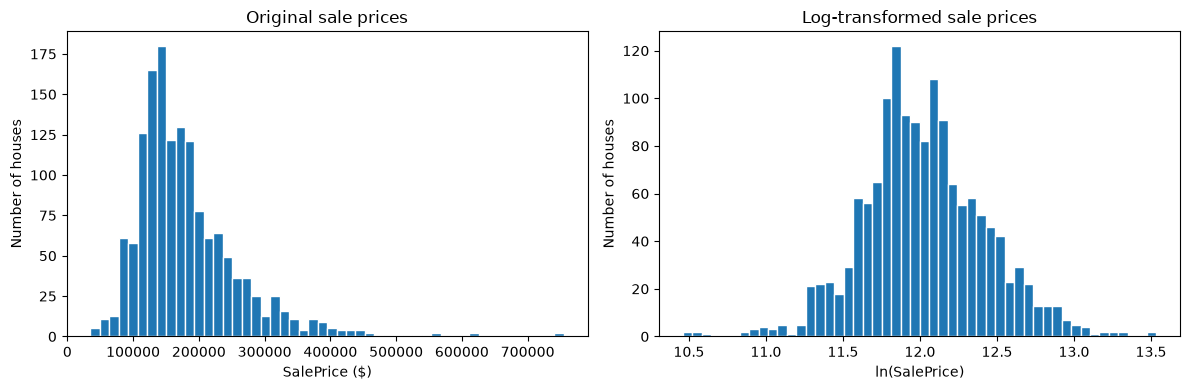

Original skewness: 1.883
Log-price skewness: 0.121


In [65]:
import numpy as np
import matplotlib.pyplot as plt
# EDA setup: display Matplotlib plots directly inside the notebook.
%matplotlib inline
import matplotlib.pyplot as plt

# EDA-T01: compare the original target with a candidate log transformation.
# This exploration label is separate from our cleaning-rule IDs.
# Keep SalePrice unchanged.
sale_price = train_clean["SalePrice"]
log_sale_price = np.log(sale_price)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(sale_price, bins=50, edgecolor="white")
axes[0].set_title("Original sale prices")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Number of houses")

axes[1].hist(log_sale_price, bins=50, edgecolor="white")
axes[1].set_title("Log-transformed sale prices")
axes[1].set_xlabel("ln(SalePrice)")
axes[1].set_ylabel("Number of houses")

plt.tight_layout()
plt.show()

# EDA-T01: compare asymmetry before and after the transformation.
print("Original skewness:", round(sale_price.skew(), 3))
print("Log-price skewness:", round(log_sale_price.skew(), 3))

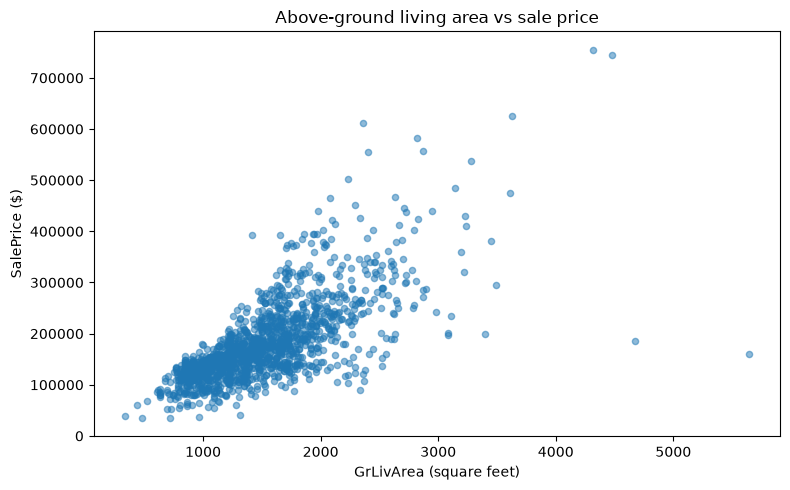

In [66]:
# EDA-R01: inspect the relationship between living area and sale price.
# Plot individual houses so unusual observations remain visible.
# No rows or values are changed.
plt.figure(figsize=(8, 5))

plt.scatter(
    train_clean["GrLivArea"],
    train_clean["SalePrice"],
    alpha=0.5,
    s=20
)

plt.title("Above-ground living area vs sale price")
plt.xlabel("GrLivArea (square feet)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

In [67]:
# EDA-R01: inspect large houses highlighted by the scatter plot.
# The 4,000 sq ft threshold is for investigation, not automatic removal.
# Include quality, condition, and sale circumstances for context.
train_clean.loc[
    train_clean["GrLivArea"] > 4000,
    [
        "Id", "GrLivArea", "SalePrice",
        "OverallQual", "OverallCond", "Neighborhood",
        "YearBuilt", "SaleType", "SaleCondition"
    ]
].sort_values("GrLivArea")

,Id,GrLivArea,SalePrice,OverallQual,OverallCond,Neighborhood,YearBuilt,SaleType,SaleCondition
691,692,4316,755000,10,6,NoRidge,1994,WD,Normal
1182,1183,4476,745000,10,5,NoRidge,1996,WD,Abnorml
523,524,4676,184750,10,5,Edwards,2007,New,Partial
1298,1299,5642,160000,10,5,Edwards,2008,New,Partial


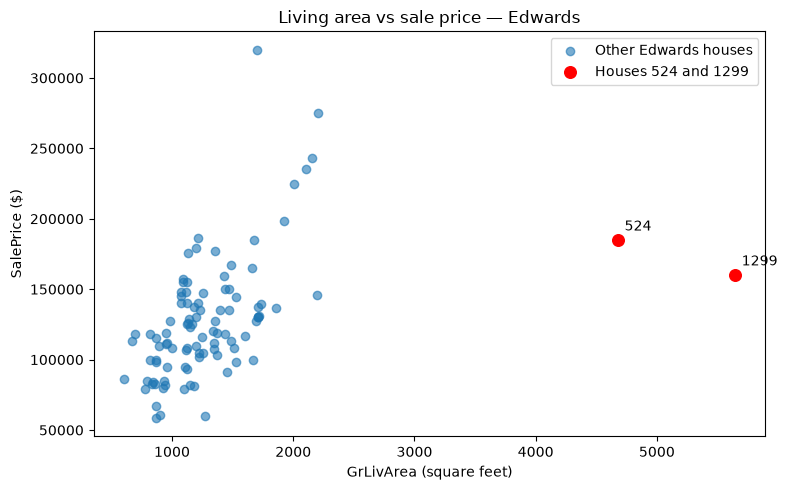

In [68]:
# EDA-R02: investigate living area and prices within Edwards.
# Highlight houses 524 and 1299; preserve all observations.
edwards = train_clean.loc[
    train_clean["Neighborhood"].eq("Edwards")
]

flagged = edwards["Id"].isin([524, 1299])

plt.figure(figsize=(8, 5))

plt.scatter(
    edwards.loc[~flagged, "GrLivArea"],
    edwards.loc[~flagged, "SalePrice"],
    alpha=0.6,
    label="Other Edwards houses"
)

plt.scatter(
    edwards.loc[flagged, "GrLivArea"],
    edwards.loc[flagged, "SalePrice"],
    color="red",
    s=70,
    label="Houses 524 and 1299"
)

for _, house in edwards.loc[flagged].iterrows():
    plt.annotate(
        str(int(house["Id"])),
        (house["GrLivArea"], house["SalePrice"]),
        xytext=(5, 7),
        textcoords="offset points"
    )

plt.title("Living area vs sale price — Edwards")
plt.xlabel("GrLivArea (square feet)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()

In [69]:
# EDA-R02: compare the highest-quality houses within Edwards.
# Examine whether quality and sale circumstances add useful context.
# No values are changed and no houses are removed.
edwards.sort_values(
    ["OverallQual", "GrLivArea"],
    ascending=[False, False]
)[
    [
        "Id", "OverallQual", "OverallCond", "GrLivArea",
        "SalePrice", "YearBuilt", "SaleType", "SaleCondition"
    ]
].head(10)

,Id,OverallQual,OverallCond,GrLivArea,SalePrice,YearBuilt,SaleType,SaleCondition
1298,1299,10,5,5642,160000,2008,New,Partial
523,524,10,5,4676,184750,2007,New,Partial
724,725,9,5,1698,320000,2007,WD,Normal
362,363,7,5,1922,198500,2003,ConLD,Normal
193,194,7,5,1709,130000,2004,WD,Normal
1088,1089,7,5,1709,137500,2004,WD,Normal
1304,1305,7,5,1708,130000,2004,WD,Normal
1254,1255,7,5,1656,165400,2003,WD,Normal
1423,1424,6,7,2201,274970,1966,WD,Alloca
175,176,6,7,2158,243000,1950,WD,Normal


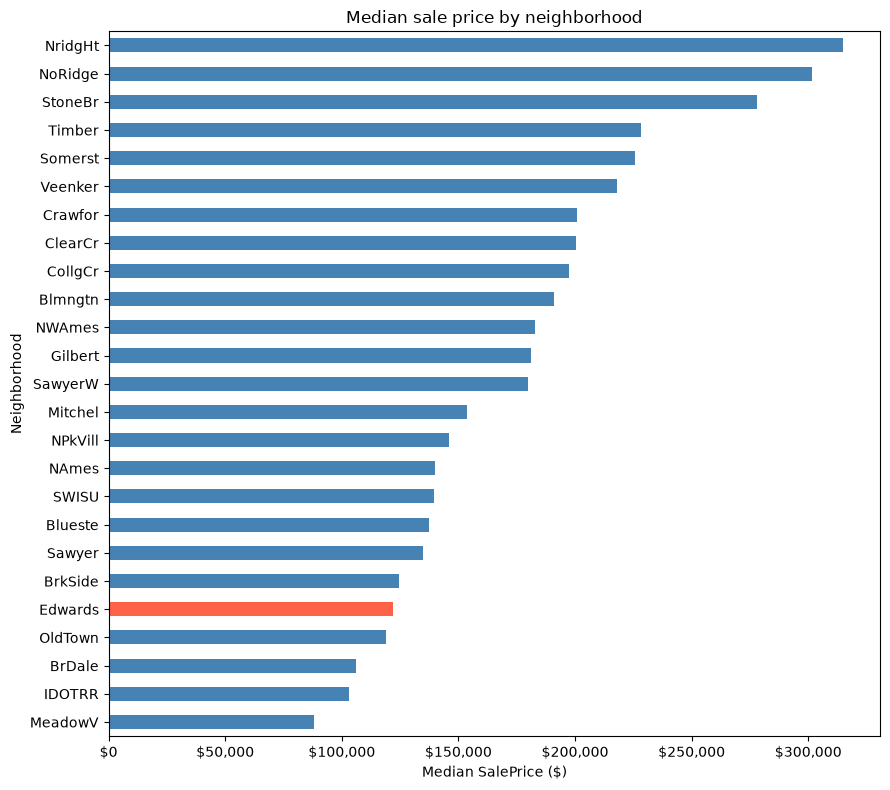

In [70]:
# EDA-R03: compare median sale prices across all neighborhoods.
# Use original dollar prices; no data are changed.
neighborhood_prices = (
    train_clean.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
)

# Highlight Edwards for comparison.
colors = [
    "tomato" if neighborhood == "Edwards" else "steelblue"
    for neighborhood in neighborhood_prices.index
]

ax = neighborhood_prices.plot.barh(
    figsize=(9, 8),
    color=colors
)

ax.set_title("Median sale price by neighborhood")
ax.set_xlabel("Median SalePrice ($)")
ax.set_ylabel("Neighborhood")

# Display prices as dollar amounts.
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"${value:,.0f}")
)

plt.tight_layout()
plt.show()